# Exploratory Data Analysis on a Natural Language Processing Task

**Content note**: This dataset contains real Facebook statuses scraped from 2009 to 2011, and some of the statuses contain language that is not safe for work, crude, or offensive. The full dataset is available as `mypersonality.csv`, and a sanitized version containing only statuses that passed an automated profanity check is available as `mypersonality_noprofanity.csv`. Please do not hesitate to use `mypersonality_noprofanity.csv` if you would prefer to. Please note that the automated profanity check is not foolproof. If you have any concerns about working with this dataset, please get in touch with your section lead.

### Summary

In this lab, you're an engineer for Facebook. In recent years, the organization Cambridge Analytica gained worldwide notoriety for its use of Facebook data in an attempt to sway electoral outcomes.

Cambridge Analytica used the Big5 personality groupings (also called OCEAN) to group people into one of 32 different groups.
- The five qualities measured by this personality assessment are:
    - **O**penness
    - **C**onscientiousness
    - **E**xtroversion
    - **A**greeableness
    - **N**euroticism
- Each person could be classified as "Yes" or "No" for each of the five qualities.
- This makes for 32 different potential combinations of qualities. ($2^5 = 32$)
- You don't have to check it out, but if you want to learn more about this personality assessment, head to [the Wikipedia page](https://en.wikipedia.org/wiki/Big_Five_personality_traits).
- There's also [a short (3-4 pages) academic paper describing part of this approach](./celli-al_wcpr13.pdf).

Cambridge Analytica's methodology was, roughly, the following:
- Gather a large amount of data from Facebook.
- Use this data to predict an individual's Big5 personality "grouping."
- Design political advertisements that would be particularly effective to that particular "grouping." (For example, are certain advertisements particularly effective toward people with specific personality traits?)

You want to know the **real-world problem**: "Is what Cambridge Analytica attempted to do actually possible, or is it junk science?"

However, we'll solve the related **data science problem**: "Are one's Facebook statuses predictive of whether or not one is agreeable?"
> Note: If Facebook statuses aren't predictive of one being agreeable (one of the OCEAN qualities), then Cambridge Analytica's approach won't work very well!

## Imports

In [116]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB

pd.options.display.max_colwidth = 400

In [165]:
df = pd.read_csv('data/mypersonality.csv')
# df.drop(columns=['NETWORKSIZE', 'BETWEENNESS', 'NBETWEENNESS', 'DENSITY', 'BROKERAGE', 'NBROKERAGE', 'TRANSITIVITY'], inplace=True)
# df.drop(columns=['BETWEENNESS', 'NBETWEENNESS', 'DENSITY', 'BROKERAGE', 'NBROKERAGE', 'TRANSITIVITY'], inplace=True)
df.head(3)

,#AUTHID,STATUS,sEXT,sNEU,sAGR,sCON,sOPN,cEXT,cNEU,cAGR,cCON,cOPN,DATE,NETWORKSIZE,BETWEENNESS,NBETWEENNESS,DENSITY,BROKERAGE,NBROKERAGE,TRANSITIVITY
0,b7b7764cfa1c523e4e93ab2a79a946c4,likes the sound of thunder.,2.65,3.0,3.15,3.25,4.4,n,y,n,n,y,06/19/09 03:21 PM,180.0,14861.6,93.29,0.03,15661.0,0.49,0.1
1,b7b7764cfa1c523e4e93ab2a79a946c4,is so sleepy it's not even funny that's she can't get to sleep.,2.65,3.0,3.15,3.25,4.4,n,y,n,n,y,07/02/09 08:41 AM,180.0,14861.6,93.29,0.03,15661.0,0.49,0.1
2,b7b7764cfa1c523e4e93ab2a79a946c4,"is sore and wants the knot of muscles at the base of her neck to stop hurting. On the other hand, YAY I'M IN ILLINOIS! <3",2.65,3.0,3.15,3.25,4.4,n,y,n,n,y,06/15/09 01:15 PM,180.0,14861.6,93.29,0.03,15661.0,0.49,0.1


### EDA on Statuses

#### Create a new column called `status_length` that contains the length of each status:

In [169]:
df['status_length'] = df['STATUS'].map(len)

#### Create a new column called `status_word_count` that contains the number of words in each status:

Note: You can evaluate this based off of how many strings are separated by whitespaces; you're not required to check that each set of characters set apart by whitespaces is a word in the dictionary.

In [170]:
df['status_word_count'] = df['STATUS'].map(lambda x: len(x.split()))

#### What are the 5 shortest statuses by status word count?

In [171]:
df.sort_values(by='status_word_count', ascending=True)[['STATUS']].head()

,STATUS
8178,157
4170,"wed,."
2016,HOUSE!
956,Err:509
4177,confused


In [172]:
df.sort_values(by='status_word_count', ascending=False)[['STATUS']].head()

,STATUS
496,"Exact words when renewing DL: Me: Oh no, you can't take my license, It's my 25th b-day. How am I going to get into the bar? DMV: We gonna give you a new one over there Me: But, it won't have my picture and stuff on it. Dmv: Hold up, we can take a picture of your picture and put it on a license i think. (yelling at co-worker to see if this can be done) Yup! Me: So, I can go to the bar?! Dmv: ..."
6989,"If I wear makeup, I'm fake. If I like to get dressed up, I'm a Tart. If I say what i think, I'm a bitch. If I cry sometimes, I'm a drama queen. If I have guy friends, I'm a slut. If I stand up for myself, I'm mouthy. Seems like you can't do anything now a days without being labeled.. So what, go ahead and label me, see if i give a shit. Repost this if your proud of who you are! x x"
5208,"can't believe it. I got the new Wii Fit Plus game, it has a lot of fun new games and features. However, after not using the wii fit for a few months we decided to do the fitness test stuff again. Me(since last time): +2.9 lbs, still a healthy weight and BMI, wii age 54. *PROPNAME*: -8.6lbs, reccommends a healthy weight of gaining 6lbs, wii age 32. On the positive side, I have lost 5 of the 8 l..."
7976,"""I said he's a fairy I do suppose//flyin thru the air in pantyhose//he may be very sexy or even cute//but he looks like a sucka in a blue and red suit//I said you need a man who's got finesse//& his whole name across his chest//he may be able to fly all thru the night//but can he rock a party til the early light//he can't satisfy you with his little worm//but I can bust you out w my Super sper..."
5680,"I always make it a rule to let the other fellow fire first. If a man wants to fight, I argue the question with him and try to show him how foolish it would be. If he can't be dissuaded, why then the fun begins but I always let him have first crack. Then when I fire, you see, I have the verdict of self-defence on my side. I know that he is pretty certain in his hurry, to miss. I never do."


### EDA of Personality 

In [180]:
for col_name in ['cEXT', 'cNEU', 'cAGR', 'cCON', 'cOPN']:
    print(f'Proportion of {col_name}:')
    print(df[col_name].value_counts(normalize=True))
    print()

Proportion of cEXT:
n    0.575534
y    0.424466
Name: cEXT, dtype: float64

Proportion of cNEU:
n    0.625151
y    0.374849
Name: cNEU, dtype: float64

Proportion of cAGR:
y    0.531162
n    0.468838
Name: cAGR, dtype: float64

Proportion of cCON:
n    0.540541
y    0.459459
Name: cCON, dtype: float64

Proportion of cOPN:
y    0.743142
n    0.256858
Name: cOPN, dtype: float64



### Visualizing status length and word count based on personality

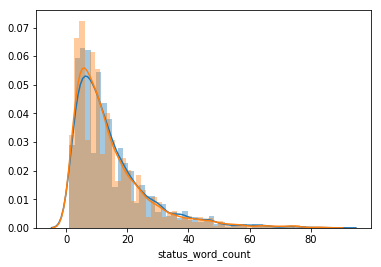

In [79]:
sns.distplot(df[df['cEXT'] == 'y']['status_word_count'])
sns.distplot(df[df['cEXT'] == 'n']['status_word_count'])

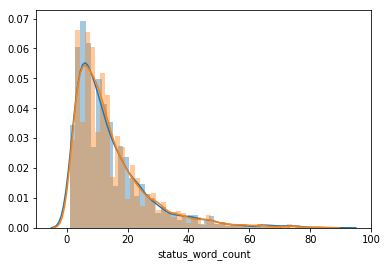

In [80]:
sns.distplot(df[df['cNEU'] == 'y']['status_word_count'])
sns.distplot(df[df['cNEU'] == 'n']['status_word_count'])

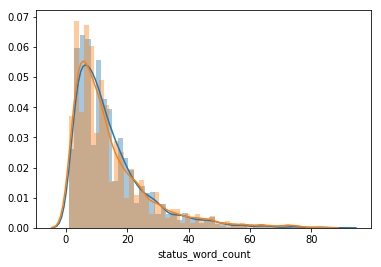

In [82]:
sns.distplot(df[df['cAGR'] == 'y']['status_word_count'])
sns.distplot(df[df['cAGR'] == 'n']['status_word_count'])

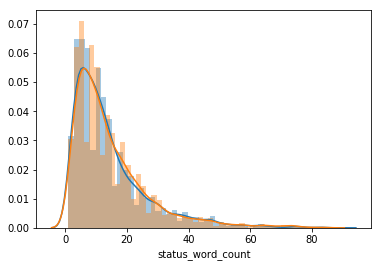

In [83]:
sns.distplot(df[df['cCON'] == 'y']['status_word_count'])
sns.distplot(df[df['cCON'] == 'n']['status_word_count'])

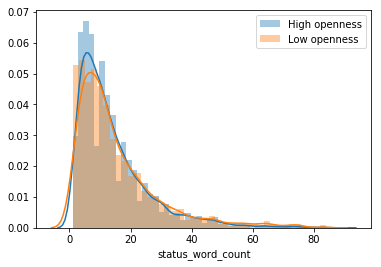

In [89]:
sns.distplot(df[df['cOPN'] == 'y']['status_word_count'], label = 'High openness')
sns.distplot(df[df['cOPN'] == 'n']['status_word_count'], label = 'Low openness')
plt.legend()

In [57]:
df.head(3)

,#AUTHID,STATUS,sEXT,sNEU,sAGR,sCON,sOPN,cEXT,cNEU,cAGR,cCON,cOPN,DATE,NETWORKSIZE,status_length,status_word_count
0,b7b7764cfa1c523e4e93ab2a79a946c4,likes the sound of thunder.,2.65,3.0,3.15,3.25,4.4,n,y,n,n,y,06/19/09 03:21 PM,180.0,27,5
1,b7b7764cfa1c523e4e93ab2a79a946c4,is so sleepy it's not even funny that's she can't get to sleep.,2.65,3.0,3.15,3.25,4.4,n,y,n,n,y,07/02/09 08:41 AM,180.0,63,13
2,b7b7764cfa1c523e4e93ab2a79a946c4,"is sore and wants the knot of muscles at the base of her neck to stop hurting. On the other hand, YAY I'M IN ILLINOIS! <3",2.65,3.0,3.15,3.25,4.4,n,y,n,n,y,06/15/09 01:15 PM,180.0,121,26


## EDA on Word Counts

### Vectorize the text

In order to perform EDA on word count data, we'll need to count-vectorize.

Create a dataframe that contains the count-vectorized text for each Facebook status in the dataset.

To do this, you might follow these steps:
- Instantiate a `CountVectorizer` object
- Fit the count vectorizer on the Facebook statuses
- Store the transformed data
- Convert to a dataframe and store
    - Don't forget that the transformed data will need to be 'densified'. The `toarray()` or `todense()` methods will allow this.
    - Don't forget that the `get_feature_names()` method on a fitted `CountVectorizer` object will bring you back the words learned from the dataset, which you can set as the `columns` argument when creating the dataframe.
    
It's up to you whether or not to keep stopwords in the dataset.

In [125]:
cv = CountVectorizer(stop_words='english')
cv.fit(df['STATUS'])

status_cv = cv.transform(df['STATUS'])
status_df = pd.DataFrame(status_cv.todense(), columns=cv.get_feature_names())

### Most common words

#### Show the 15 most common words:

In [126]:
status_df.sum().sort_values(ascending=False).head(15)

propname    1309
just         717
day          534
like         506
time         424
going        414
today        402
new          386
work         369
good         354
got          314
night        312
love         292
tomorrow     277
know         276
dtype: int64

#### Show the 15 most common words as a bar chart:

Hint: You can do this in one line of code. [This webpage](https://dfrieds.com/data-visualizations/bar-plot-python-pandas.html) has an example.

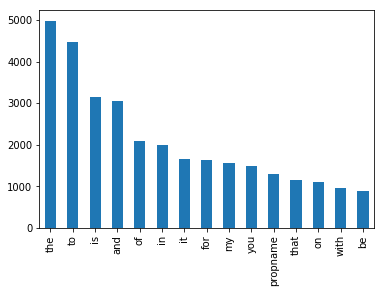

In [123]:
status_df.sum().sort_values(ascending=False).head(15).plot(kind='bar')

### Investigating `propname`

The word `propname` shows up frequently in this dataset. Show the first 10 statuses in the dataset that contain `propname`:

In [102]:
[status for status in df['STATUS'] if 'propname' in status.lower()][:10]

['saw a nun zombie, and liked it. Also, *PROPNAME* + Tentacle!Man + Psychic Powers = GREAT Party.',
 'is tired. *PROPNAME*, let me go to sleep pl0x.',
 'has a fair idea of how to manage the 2.5 kids cliche... She just needs a very strong gentleman named *PROPNAME* and thriteen wet napkins.',
 'has a serious crush on *PROPNAME*. <3',
 'Mondays are the new thursdays- anthony bourdain + *PROPNAME*  = forgetting your financial troubles',
 "is *PROPNAME*'s bestbian",
 'is in love with *PROPNAME*.',
 'is in love. With *PROPNAME*.',
 "Ten Movies to Watch Right Now (and some you can Instant Netflix) 1. La Vie En Rose 2. Shrink (if you love LA) 3. Paris Je'taime (if you love Paris) 3. Clay Pidgeons (*PROPNAME* is priceless) 4. Quills 5. Away We Go 6. Sunshine Cleaning 7. A League of Their Own 8. Smart People (I Heart *PROPNAME*'s Page and SJP) 9. Frost//Nixon 10. Doubt",
 'ATTENTION EVERYONE!!! Vote for the short "AFTER HOURS" to support *PROPNAME* - our local Michigan talent and a wonderful pe

#### Provide a short explanation of what you believe `propname` to be:

Hint: The attached PDF also contains an explanation.

Try to find some famous people who may have been discussed during 2009-2011...

In [118]:
[each for each in df['STATUS'].str.lower() if 'obama' in each]

['prøver å forsvare obama til min norsk romkamerat på norsk og det er utrolig vanskelig.',
 'can obama will the us to victory over brazil sunday?',
 'obama won the nobel peace prize!!!! laaaaaaaammmme!',
 'an obama consultant yesterday on taxing high-value, middle class health care plans: "we\'re not talking about a new tax on these people. we\'re saying they currently get an enormous tax break and we\'re going to slightly scale that back . . ." this will likely be the talking point for any new, middle-class taxes to come.',
 'is shaking his head wondering when some of his conservative christian friends became so hate filled that they will join any anti-obama group on facebook.',
 '@_@ turkeyday for me = a bunch of republicans coming together eating a huge feast and obama bashing....its disgusting!',
 'is temporarily upset with obama for being in a commercial with *propname*.',
 'is watching obama represent chicago2016... fingers crossed for tomm afternoon!',
 'president obama -- fight